# Tracking a contact-normal line

**How do known requests identify an unknown constraint, and what does its directional uncertainty change?**

A contact normal is an **unoriented line** $[n_t]$: $n_t$ and $-n_t$ describe the same tangent plane. We first connect force balance to the draft's conditional likelihood, then inspect genuine antipodal Bingham densities on the unit sphere. Independent benchmarks separate the value of the likelihood, the mean, and global distribution shape. Higher-dimensional examples represent generalized linear constraints, rather than pretending a high-dimensional posterior is a 3D sphere.

The physical model is maintained ideal bilateral contact with known isotropic resistance. It has no friction cone, detachment, impact or unknown mobility metric. The earlier executed contact experiments remain [archived](../results/simulation_redesign/archive/03_contact_2a8697c.ipynb) with their original certificates and assumptions.

In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
from IPython.display import Image, display, Markdown
ROOT = Path.cwd() if (Path.cwd() / 'lib').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from lib.plotting import plt
from lib.simulation_story_visuals import load_studies
from lib.simulation_validation import verify_legacy
from scripts.make_geometry_notebooks import verify_summary
D = load_studies(ROOT, 'paper')
from lib.simulation_validation import require_gate
SUMMARY = verify_summary(require_gate(ROOT))
BASE = D['base']
F = BASE / 'figures'
FIG = json.loads((F / 'manifest.json').read_text())
assert FIG['profile'] == 'paper'
assert plt.rcParams['text.usetex'] is True
assert plt.rcParams['figure.dpi'] == plt.rcParams['savefig.dpi'] == 200
for mapping in ('sources', 'input_manifests'):
    for name, expected in FIG[mapping].items():
        assert hashlib.sha256((ROOT / name).read_bytes()).hexdigest() == expected

def show(name):
    path = F / (name + '.png')
    assert hashlib.sha256(path.read_bytes()).hexdigest() == FIG['files'][path.name]
    display(Image(filename=str(path), width=1400))
    display(Markdown(FIG['captions'][name]))

print('Verified the current theory gate, four paper components, figures and findings.')

Verified the current theory gate, four paper components, figures and findings.


## C1. From applied force to the measured response

With known isotropic resistance $dI$, the free requested velocity is $v_t=F_t/d$. The plant independently solves force balance and $n_t^\top\bar u_t=0$, giving the closest admissible velocity $\bar u_t=P_{\mathcal X_t}v_t$, $\mathcal X_t=n_t^\perp$. The measurement is $u_t=\bar u_t+e_t$, $e_t\sim\mathcal N(0,sI)$.

The estimator receives the request and noisy response, not the surface normal or constraint projector. A measured wrist orientation determines the supplied frame transport $G_t$ and is shared with every comparator. Signs of normals are aligned only for display/scoring. The force balance in this first figure explains the geometry; it does not provide the hidden normal to estimation.

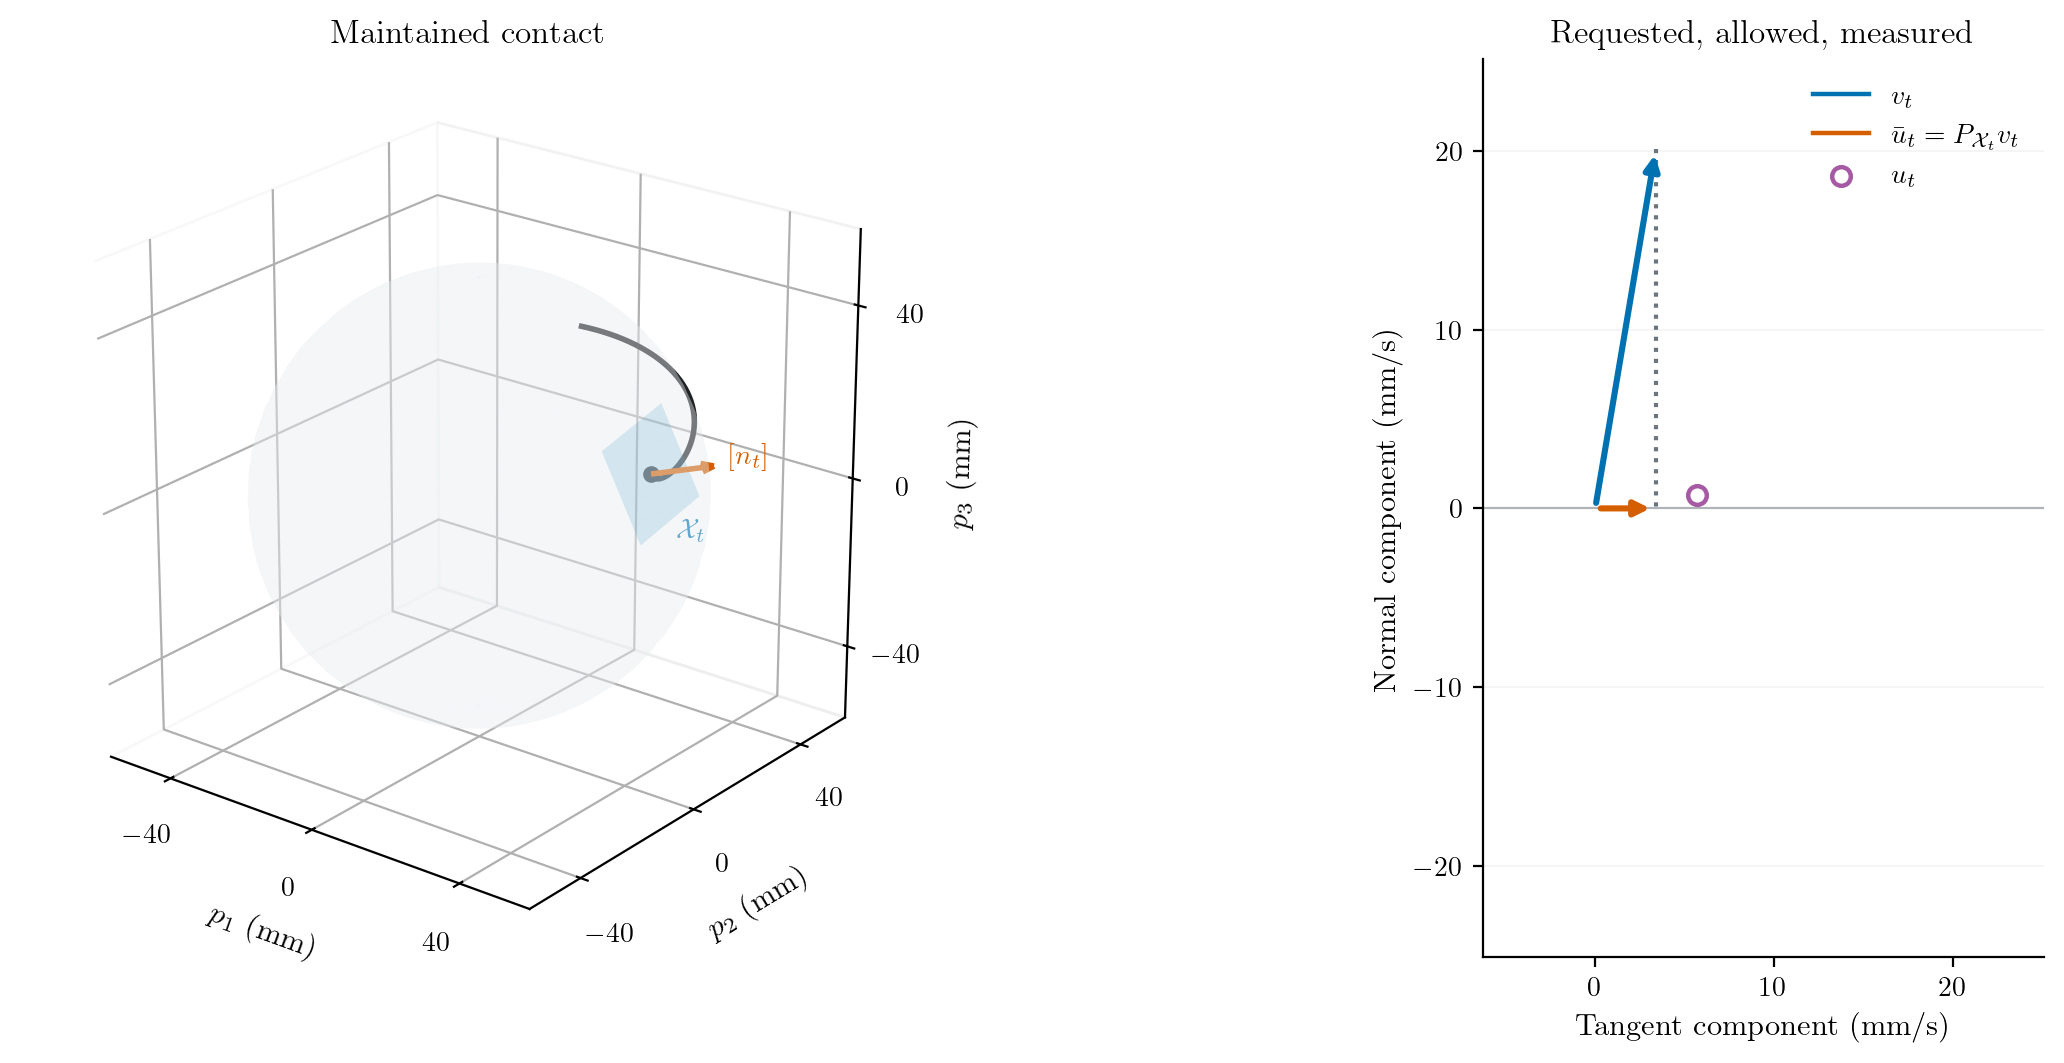

The plant solves ideal maintained bilateral contact with known isotropic resistance. Its clean velocity is the Euclidean projection of the requested free velocity. True geometry appears only in this explanatory rendering and in scoring. The estimator observes the request, noisy realized response and measured wrist orientation. The normal is an unoriented line $[n]$: $n$ and $-n$ describe the same constraint plane.

In [2]:
show('contact_01_mechanics')

## C2. Known requests create directional information

The conditional correction is $B_t=(u_tv_t^\top+v_tu_t^\top-v_tv_t^\top)/(2s)$. The negative term matters: a blocked request $u_t\approx0$ still informs the normal. Identical-likelihood spectral least squares is the modal reference. PCA of residuals uses the known requests as well; velocity-only PCA would discard available information and would be a weaker comparison.

For a tangent-plane parameter $A_t^+$, the normal-line density is $q_{-A_t^+}([n])$, and the plane mean is $\overline P_t^+=I-\mathbb E[nn^\top]$. The mean of a signed normal itself is zero by antipodal symmetry. The next figure compares two equal-energy request programs at the same reporting time: cyclic coordinate axes and requests near $e_1$.

The expected Fisher eigenvalues follow the draft's $F_t=(C_{11,t}\otimes I+I\otimes C_{22,t})/s$. They describe expected information at the stated state, not the realized posterior curvature. A small input-Gram eigenvalue alone does not imply weak local information; the direction relative to the normal matters.

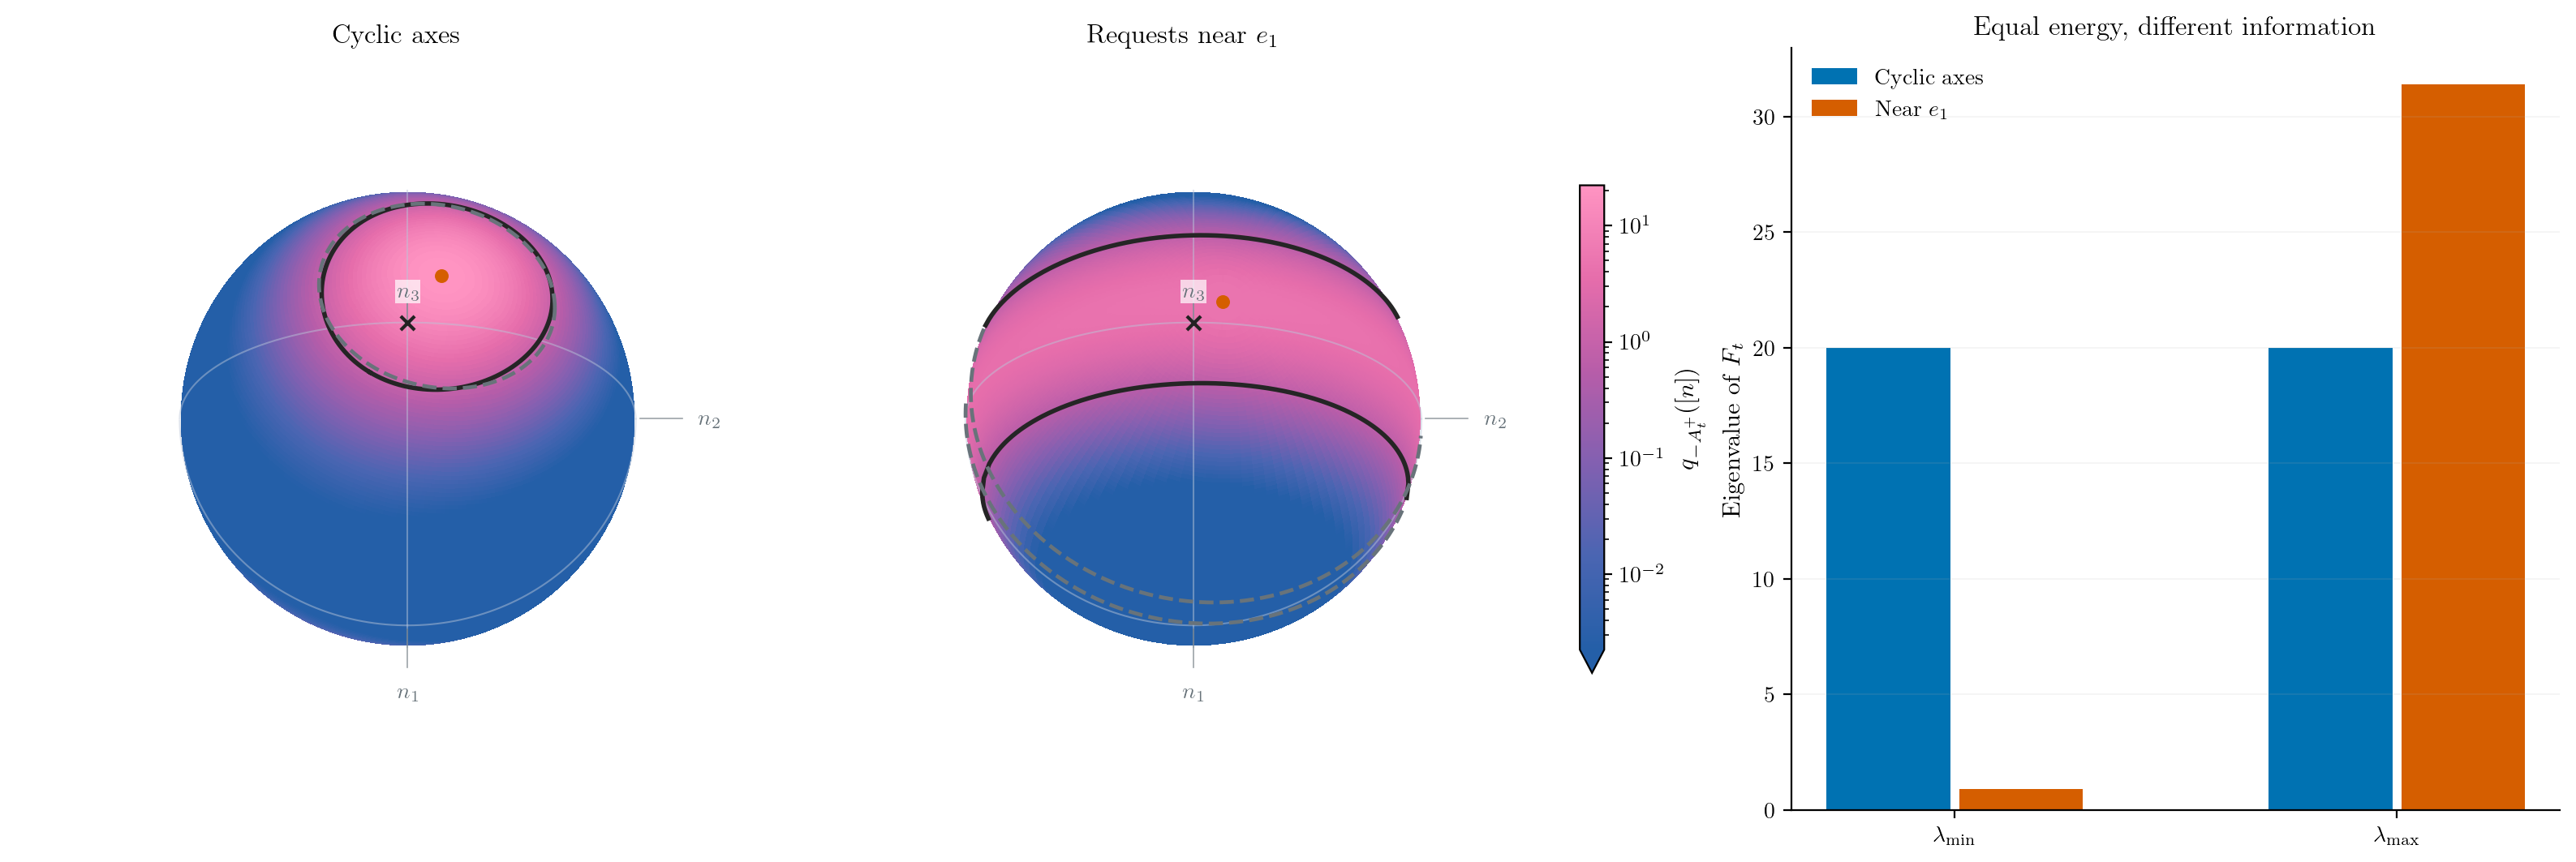

Actual post-correction normal laws $q_{-A_t^+}$ at $t=8$ for two equal-energy request programs. Colors are densities relative to normalized invariant measure $d\Omega/(4\pi)$; antipodal points describe one plane. The expected conditional Fisher information is evaluated at the true fixed normal for explanation, not supplied to the estimator. It is different from the realized posterior curvature. Solid dark outlines are state HPD boundaries; gray outlines are centered chordal balls.

In [3]:
show('contact_02_posterior')

## C3. The same mode and radius can hide different commands

The draft's deterministic example has $A^{(1)}=\operatorname{diag}(0,-8,-80)$ and $A^{(2)}=\operatorname{diag}(0,-80,-8)$. Here these are **normal-line** parameters; their dual tangent-plane parameters are $-A^{(i)}$. The modes and entire centered chordal-distance distributions agree, but the mean-response risks for $e_2$ and $e_3$ differ by about tenfold.

For contact motion, Eq. (34) predicts $\overline P_t^+v$ and gives clean-response risk $v^\top[\overline P_t^+-(\overline P_t^+)^2]v$. The full vector covariance needs second moments; this scalar total risk uses the mean only. Eq. (36) chooses $v_t^{\rm B}=[I+\lambda(I-\overline P_t^+)]^{-1}v_t^{\rm des}$. The two beliefs below yield different commands for the same desired vector, even though one mode and one radius cannot distinguish them.

This is an expected-penalty command, not a guaranteed feasible controller. The HPD and distance ball each have posterior mass 0.95; equal mass does not make one tighter in every direction. Bounds in the tables concern the blocked normal projection $\|nn^\top v\|$, rather than tangent-plane speed.

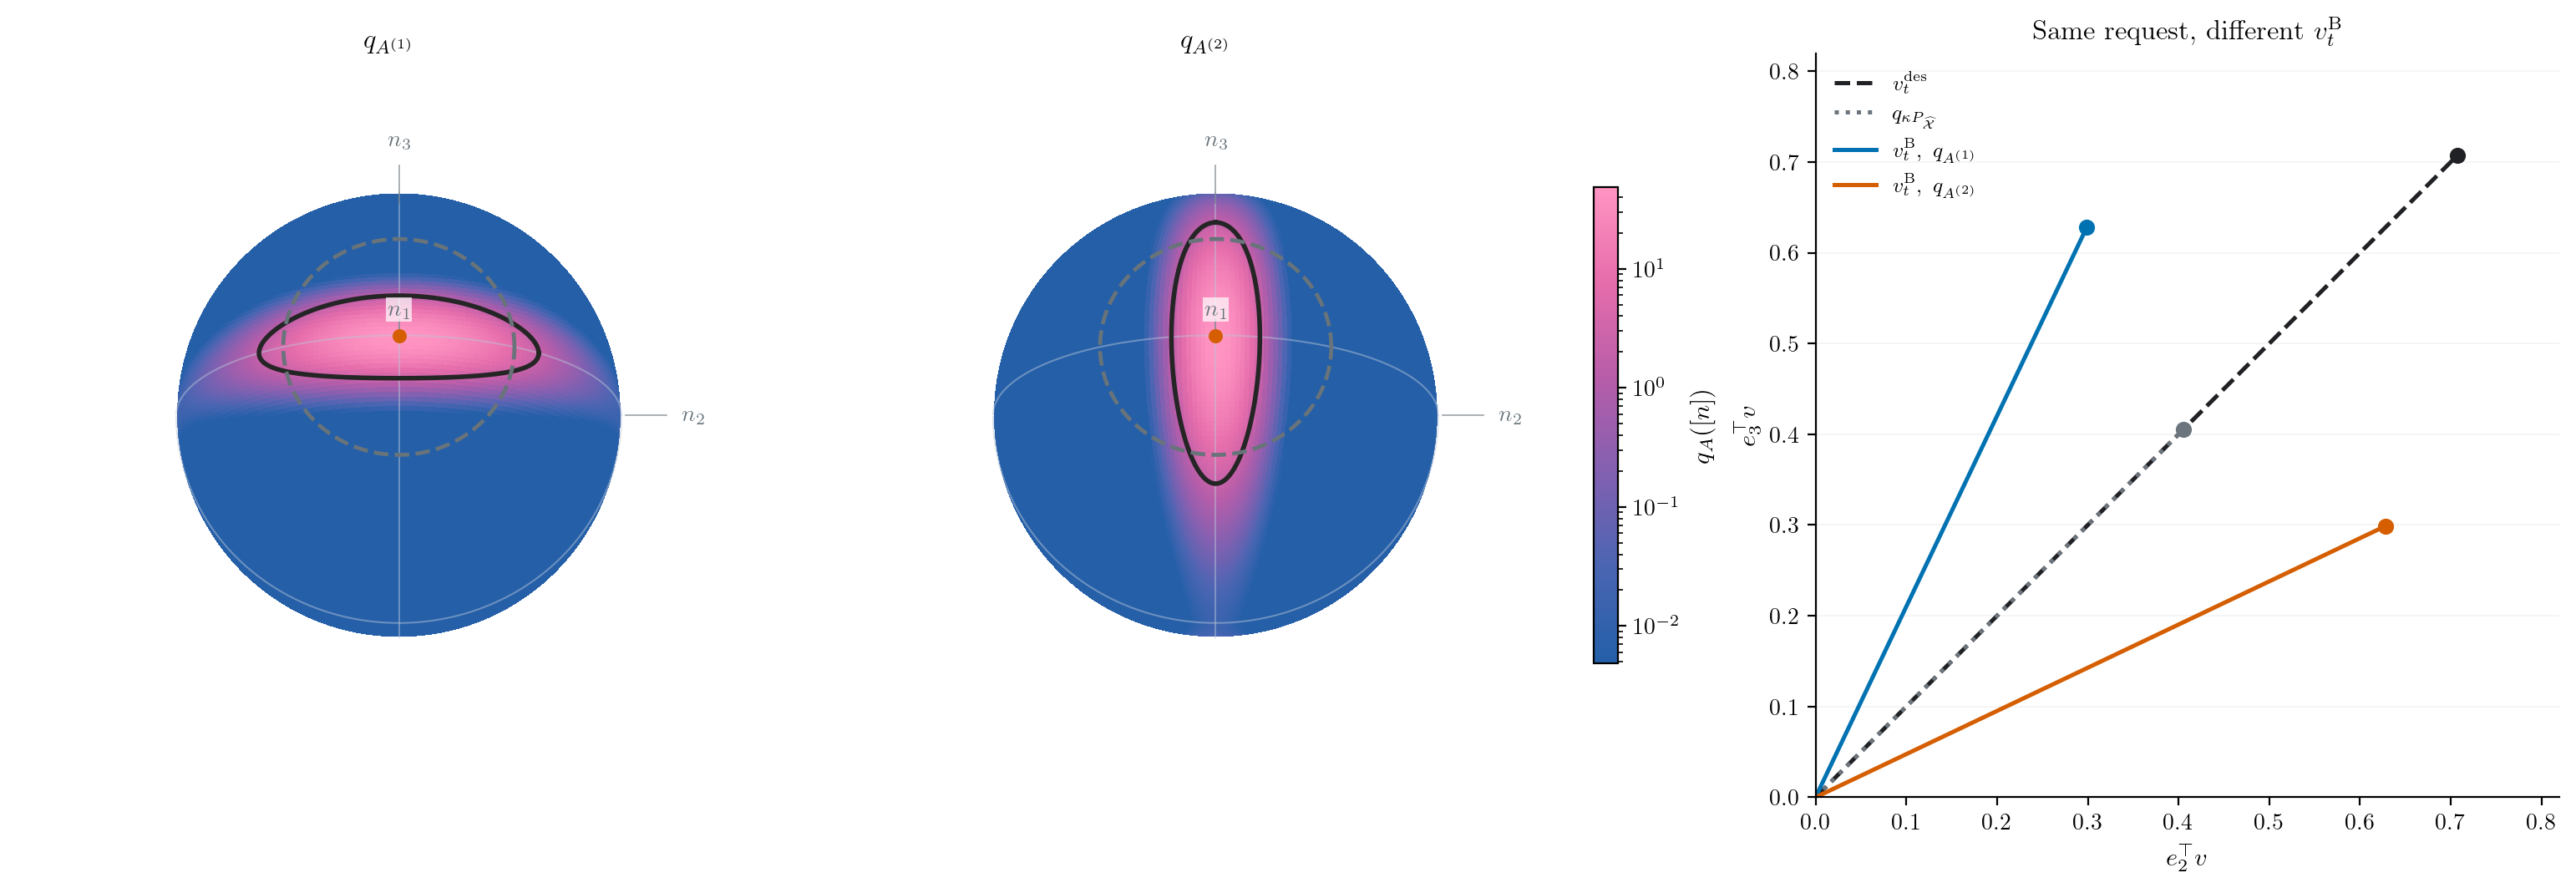

The real $\mathrm{Gr}(1,3)$ example in the draft is interpreted as a contact-normal line: the tangent-plane mean is $I-\mathbb E[nn^\top]$. Both beliefs have the same mode and every centered distance quantile. The right panel uses the same $v_t^{\rm des}$ and $\lambda=20$ in Eq. (36); $v_t^{\rm B}$ is an expected-penalty action, not a guaranteed feasible contact controller. Region bounds in the tables concern the blocked normal component $\|nn^\top v\|$, not admissible-plane speed.

In [4]:
show('contact_03_directional')

## C3. Do the mean and its directional structure improve actual loss?

The fresh stationary benchmark uses independent Haar normal lines, equal-energy requests and known sensor variance. References include the identical-likelihood point estimate, matched axial uncertainty, validation-regularized spectral response $\widetilde M_t v$, ridge regression, residual PCA, and a local Gaussian approximation with its validity flags. The axial tangent-plane law $q_{\kappa P_{\widehat{\mathcal X}_t}}$ is equivalently $q_{\kappa P_{[\widehat n_t]}}$ on normal lines; it matches the normal modal overlap and $r_{t,\mathrm{rms}}$.

The paired response plots and soft-command costs answer different questions. Ridge regression is eligible as a response-map estimate; it is not inserted into a formula requiring a positive projector mean. The local $\mathcal N(0,H_t^{-1})$ approximation is pushed through the modal tangent exponential; it is different from the recursive extended Kalman filter used for physical tracking. Broad or unresolved local charts remain flagged, rather than being treated as global distributions.

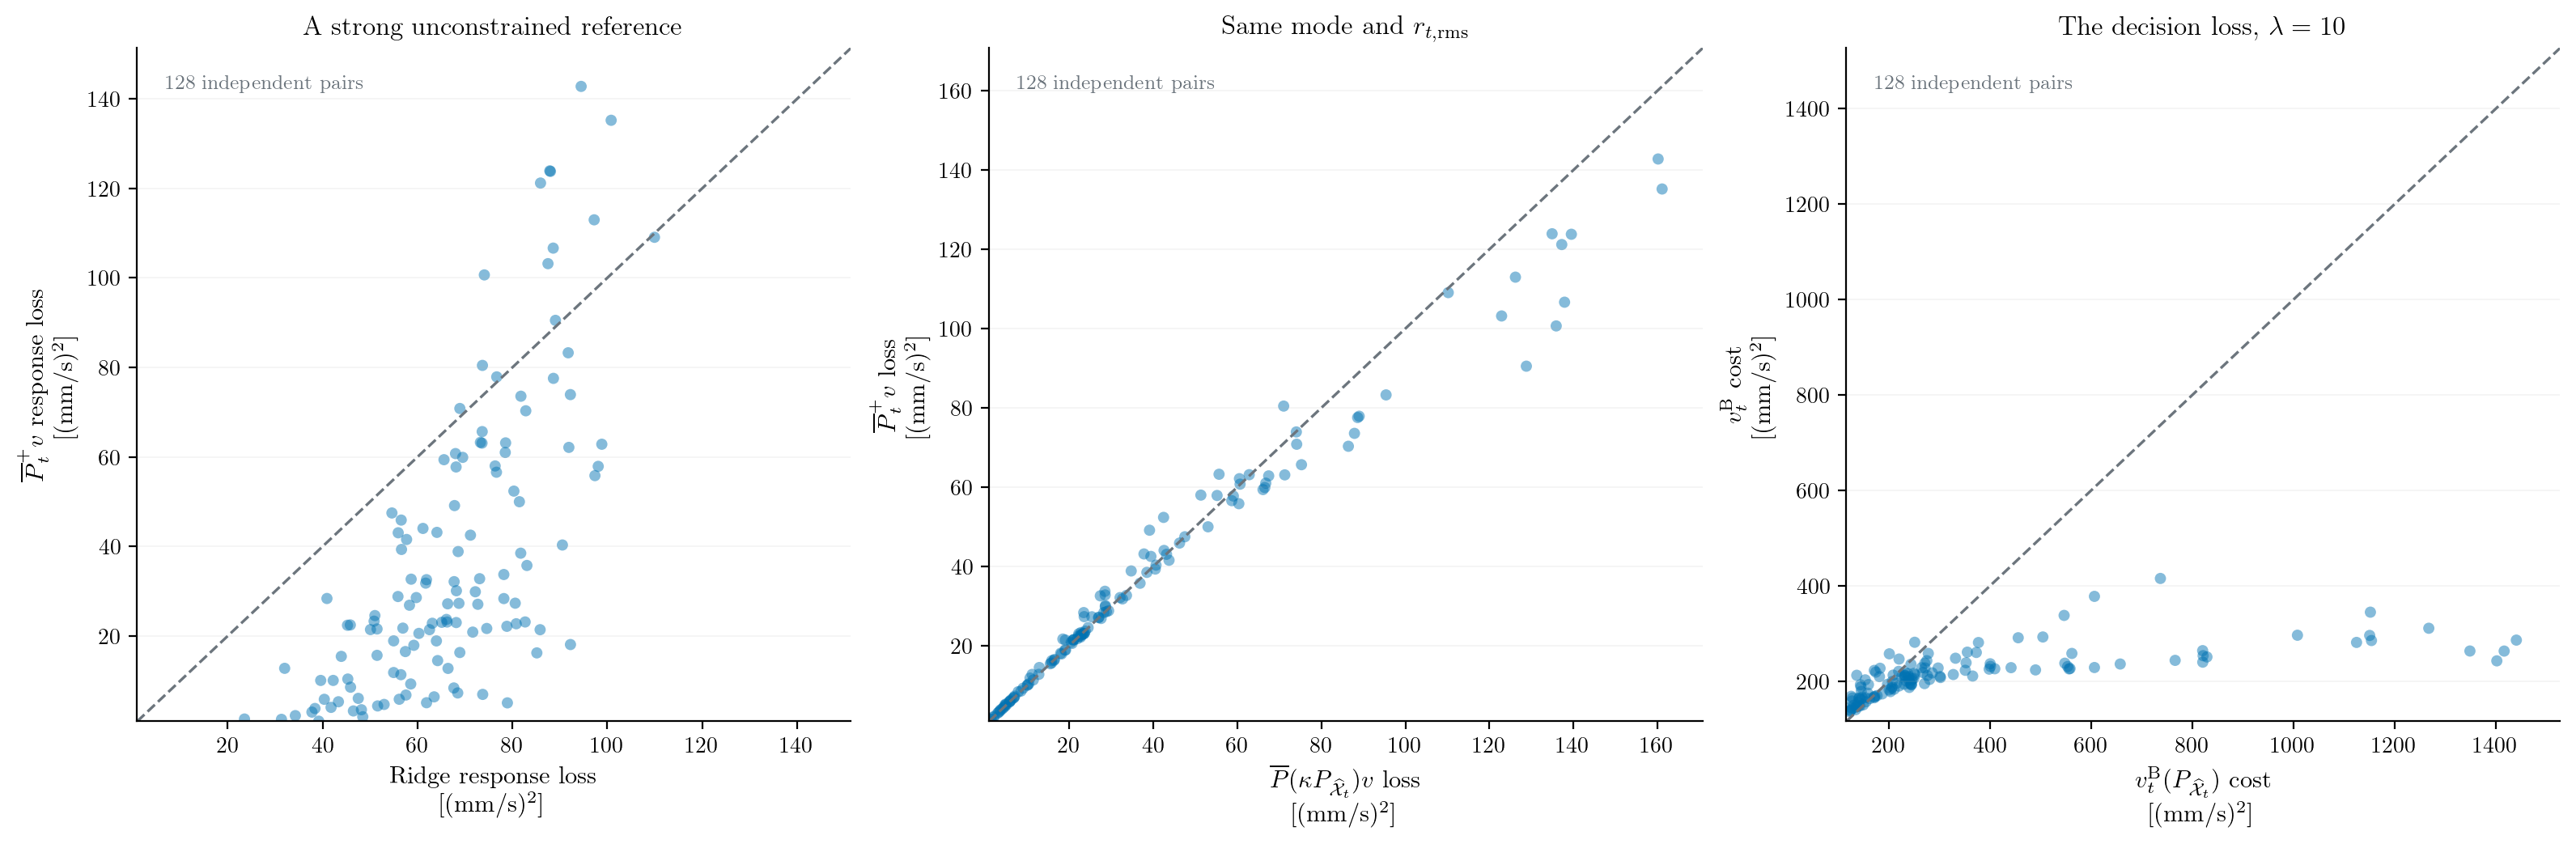

Paired independent stationary trajectories with requests near $e_1$, $t=8$. Response losses and Eq. (35) command costs are in $(\mathrm{mm}/\mathrm{s})^2$. Ridge regression is a strong response-map reference and is not assigned an invalid projector-based command. Matched axial uncertainty preserves the modal normal and its expected squared chordal distance. The command panel uses $\lambda=10$. Complete baselines, local-Gaussian validity flags and both request programs remain available.

In [5]:
show('contact_04_benchmarks')

## C1; C3. Track the normal as the contact and coordinates change

On the physical sphere the admissible plane changes even in the world frame. Wrist motion adds a measured coordinate change, handled by $A_t^-=\beta G_tA_{t-1}^+G_t^\top$. It does not reveal the changing surface geometry. Each practical method receives the same measured rotations and independently selects its declared memory/noise settings on validation data.

The response distributions are **post-correction, current-state** predictions for a fresh request at the present contact, not forecasts of a future surface. Their central intervals are posterior statements. Finite numerical mass checks do not establish frequentist coverage under drifting states. The theorem's fixed-time modal bound pays for residual drift and can fail its sufficient condition; invalid bounds stay invalid in the tables. Known frame transport, improved memory and distribution shape are different effects.

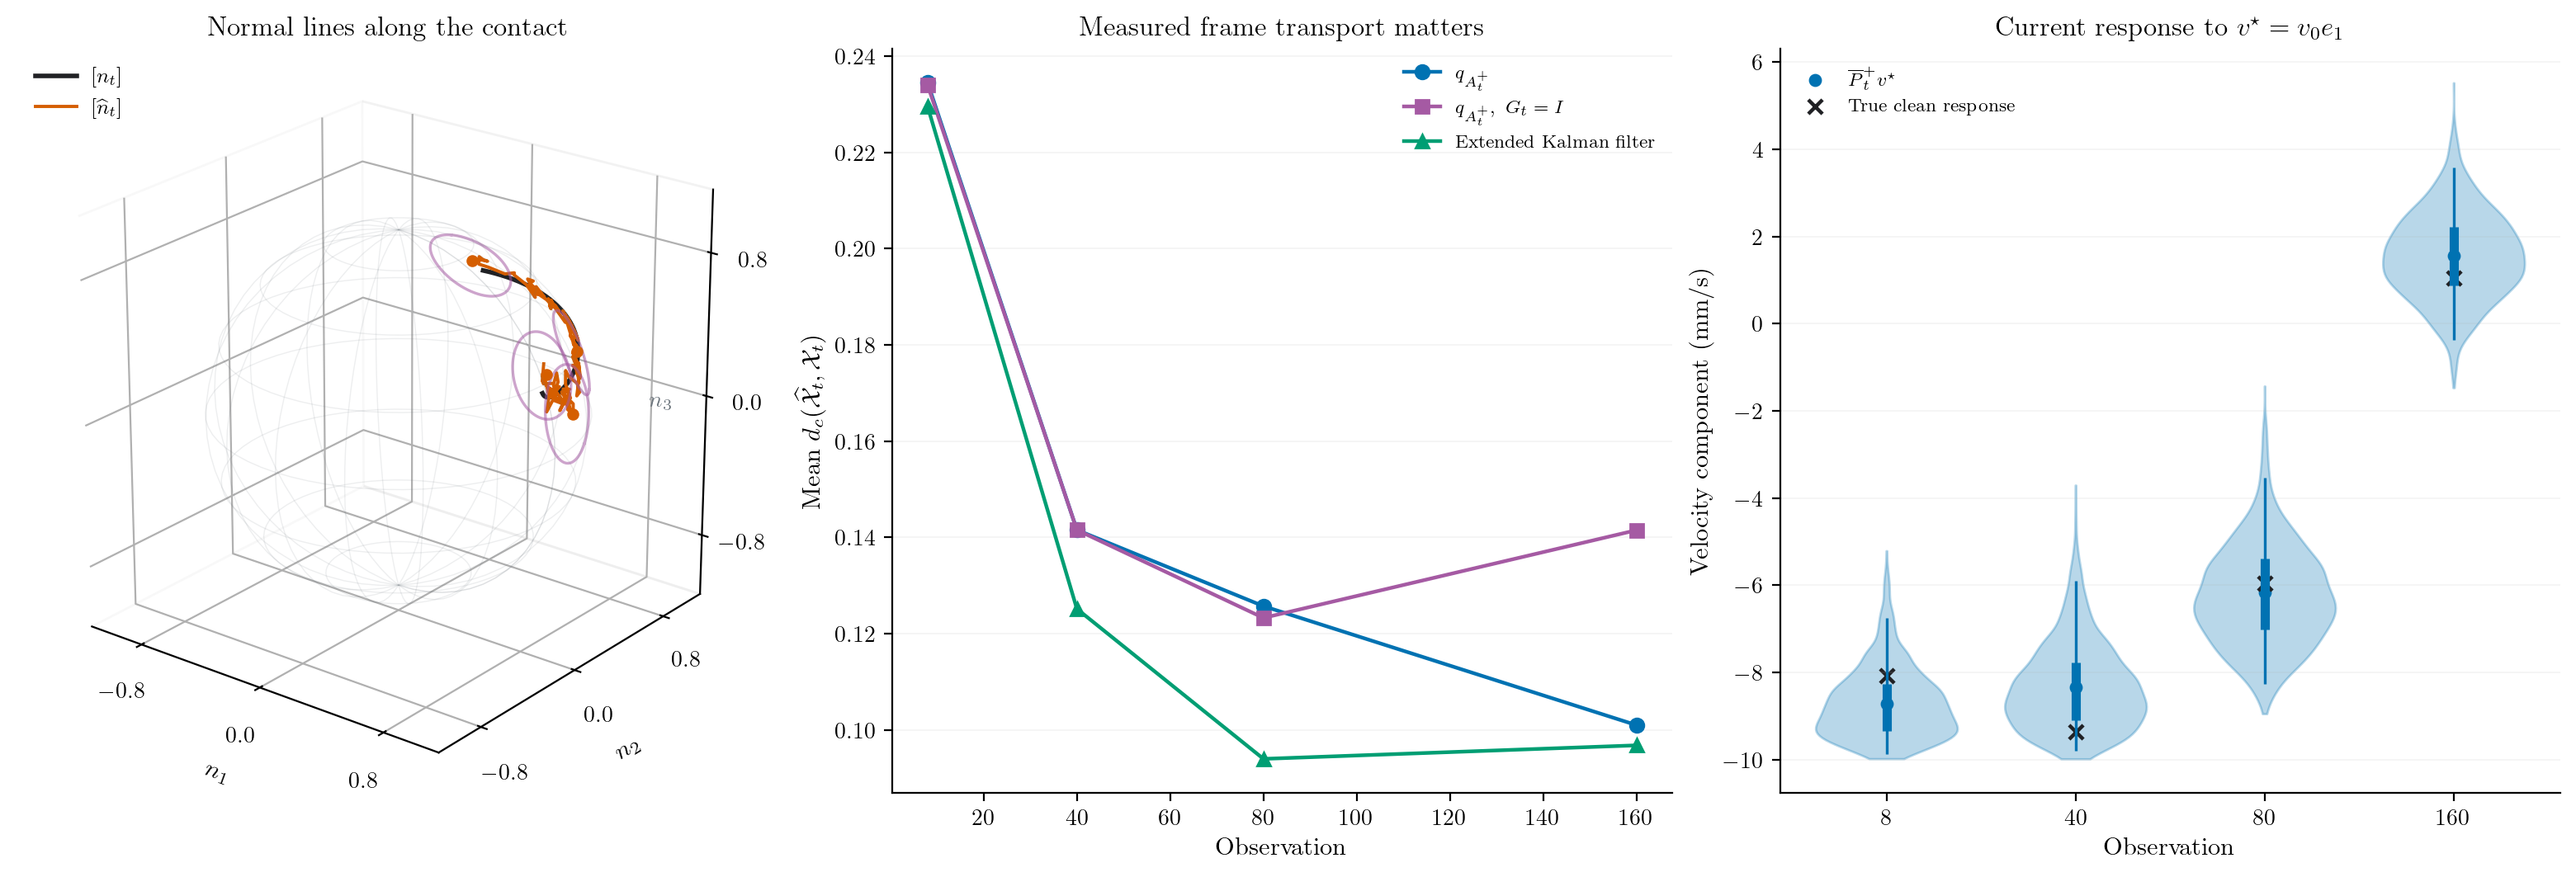

The normal line evolves along an independently generated physical sphere. Measured wrist-frame rotations are supplied equally to every practical method; they do not reveal the changing surface normal. Signs are aligned only for this display/scoring. The middle panel averages modal state errors over independent trajectories; $\overline P_t^+$ is not assigned a modal normal. The response violins are post-correction, current-state counterfactual predictions for $v^\star=v_0e_1$, at predeclared report times. Visual particles are resampled integration nodes; checked central 50%/95% quantiles come from continuous integration. This is not a future forecast or a repeated-data coverage claim. Each dynamic method selects its own validation memory; the same-$A$ shape controls are separate.

In [6]:
show('contact_05_tracking')

## S1. Beyond three coordinates

The same conditional model describes an unknown codimension-one linear constraint in $\mathbb R^N$. These generalized velocity examples use $N=8,16,32$ and $t=4N$ requests. No robot Jacobian is hidden from a structured competitor, and these are not claimed as a physical high-DOF robot simulation.

For isotropic test requests, average response MSE contains a factor $1/N$. It can decrease merely because one constraint occupies a smaller fraction of the ambient space. The figure therefore shows full response-map Frobenius error instead. The separate timing cohort has a fixed 64-observation horizon and uses native rank-one complement calculations. It measures computational scaling, not mechanical-controller latency or an arbitrary-rank solver.

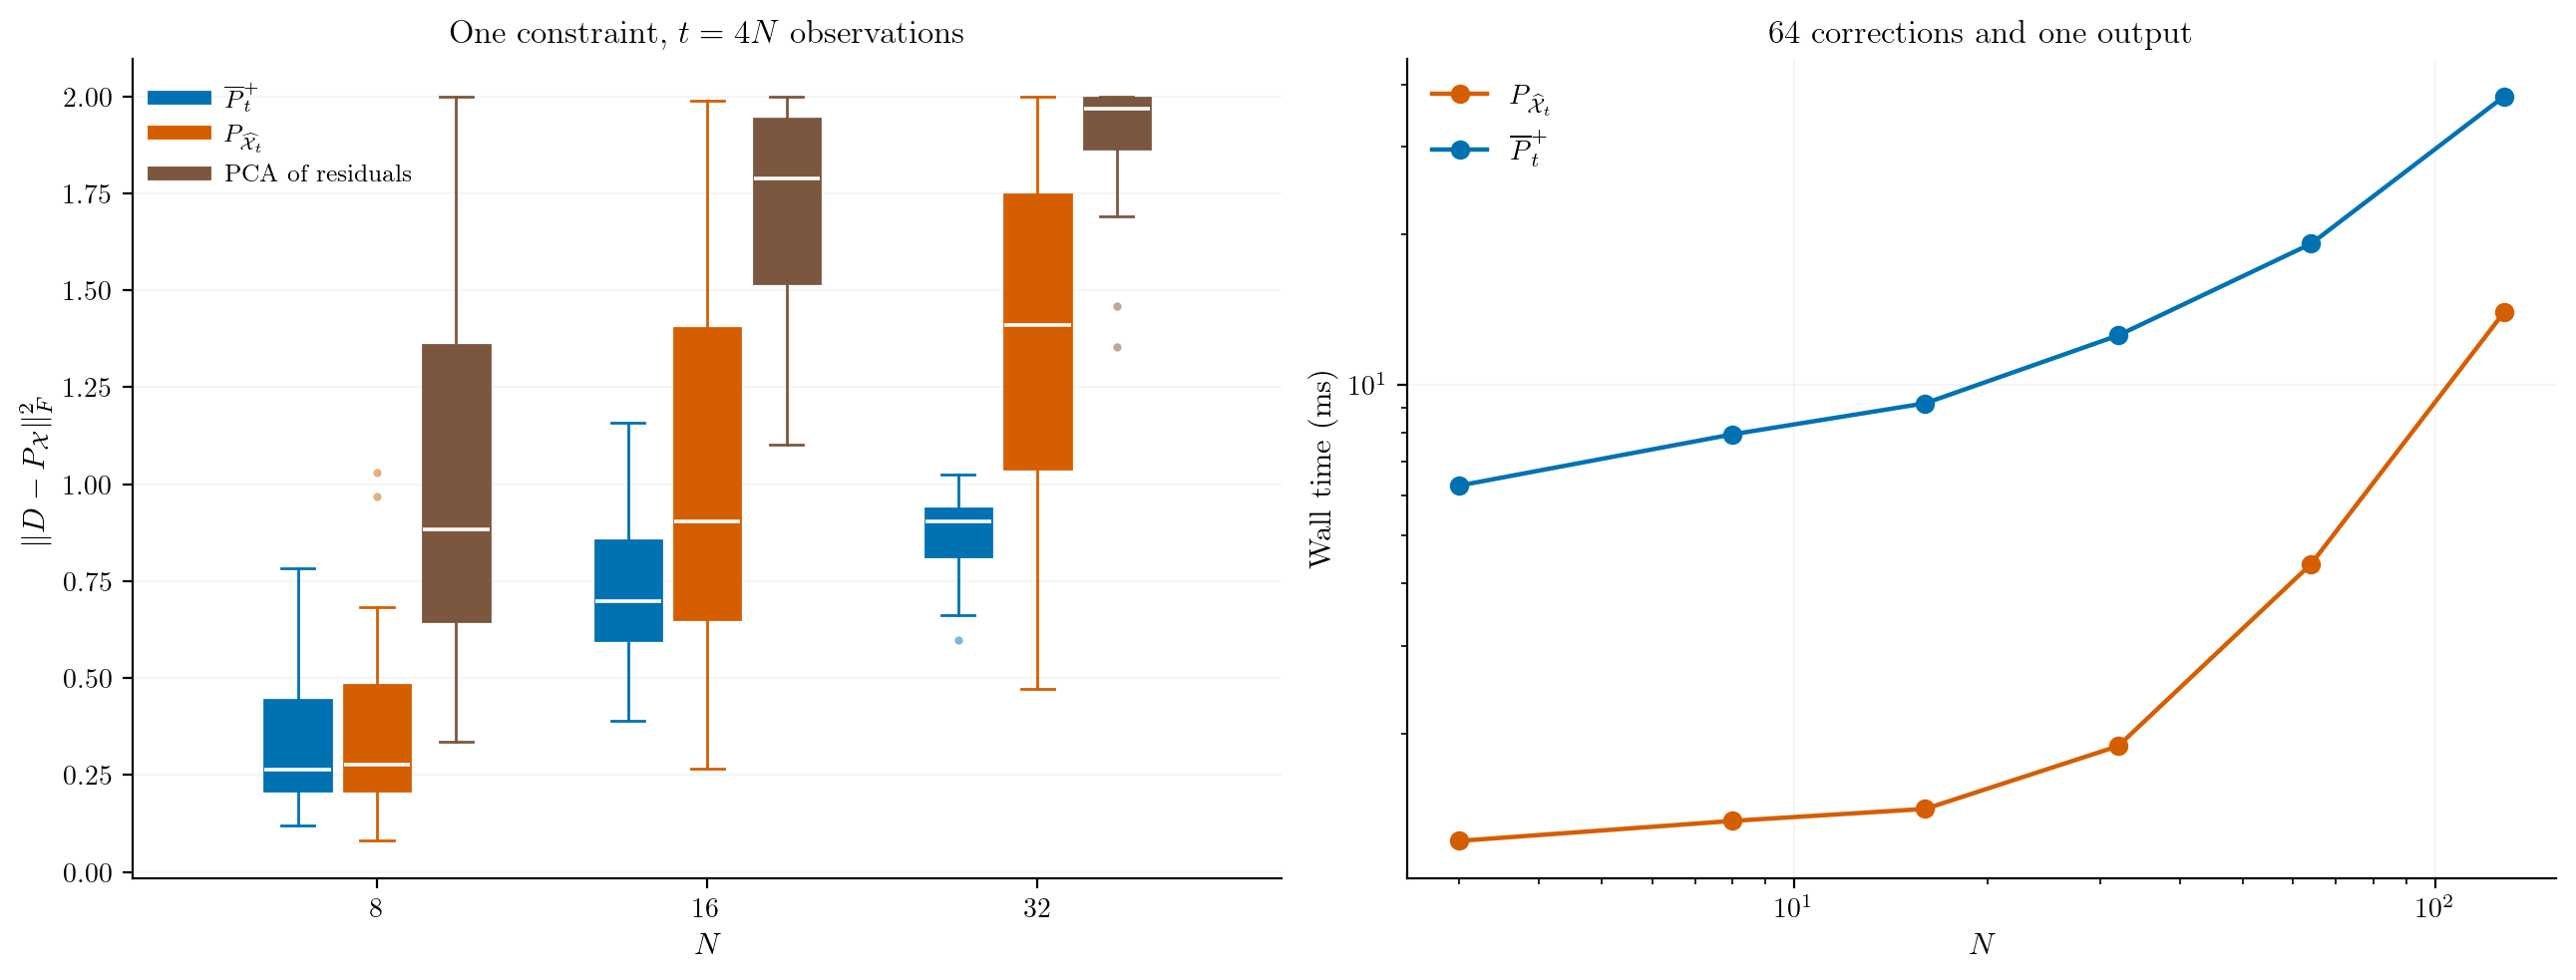

These are generalized single linear maintained constraints, not a fabricated high-DOF robot with known Jacobians withheld from a comparator. The accuracy cohort uses $t=4N$ requests and plots Frobenius response-map error, avoiding the artificial $1/N$ reduction in average isotropic-query MSE. The separate serial timing cohort uses 64 dimensionless observations and one endpoint output; it is not mechanical-controller latency. Generic-rank moments are not substituted for the native rank-one/complement backend.

In [7]:
show('contact_06_higher_dimension')

## What the independent experiments show

In [8]:
display(Markdown((ROOT / 'results/simulation_redesign/contact_summary.md').read_text()))

The contact paper study observes applied requests and noisy realized velocities, using the real conditional likelihood. Normal densities are antipodally symmetric Bingham distributions on the sphere, with parameter $-A_t^+$ for a tangent-plane parameter $A_t^+$. Equal-energy input programs change the directional information without changing command magnitude. The conditional correction can retain anisotropy from one observation. Static response comparisons give mode: 11 gains/0 losses in 12 cells; matched modal-overlap control: 8 gains/0 losses in 12 cells; ridge regression: 12 gains/0 losses in 12 cells. Against the independently validated extended Kalman filter, physical tracking gives 0 gains/2 losses/1 unresolved in 8 cells. Only complete numerical/local-validity comparisons are resolved; raw finite differences and every invalid chart are retained. These cellwise intervals have no multiplicity guarantee.

The swapped-axis beliefs have identical mode and every centered distance quantile, yet different response risks and soft expected commands. This isolates directional structure. A modal point estimator with the identical likelihood remains exactly the same modal estimate; gains from known inputs or frame correction are not full-distribution gains. The $N=8,16,32$ cases are generalized single constraints, not fabricated high-DOF robot contacts. Conditional bounds retain valid and invalid conditions at fixed times. The expected command is a soft penalty, not a guaranteed feasible contact controller. Global density integration, repeated-data calibration, local Gaussian validity and computation are reported separately.


## Interpretation and reproducibility

The full mean predicts an expected velocity; it is generally not one feasible contact projector. The matched same-mode/spread and same-parameter Gaussian controls isolate information beyond a point estimate, while the physical comparison also includes dynamics and numerical approximation. Benefits must be supported by independent response/action loss, uncertainty width/score or global geometry, with computation included. A known-force likelihood or supplied frame rotation can benefit point methods too.

The fixed-state visual story uses a coordinate-aligned true normal and coordinate requests. Some scalar responses then lie at support boundaries, so finite central intervals can exclude them even under the correct likelihood. This does not contradict posterior mass or a state-region coverage result. The independent Haar-normal cohort and the single displayed physical trajectory have different probability interpretations.

Read the [findings](../results/simulation_redesign/findings.md), [reproduction protocol](../results/simulation_redesign/README.md), and [notation/assumptions](../docs/simulation_redesign_notation.md). Noise is fixed in this notebook's original comparison cohorts. The added [implementation supplement](04_implementation_audit.ipynb) separately implements and checks fixed-boundary-block EM; it distinguishes that objective from the historical per-observation-prior routine. These fixed-scale comparisons do not claim a scale-learning advantage. Historical temperature, learned-motion and stochastic-process studies remain separately labelled in the archived notebook. No code or inference is rerun merely to adjust a figure layout.